# Quantum Metal A.5 — launch-video chip: four-qubit ring with charge lines and readouts (Quantcore PDK rebuild)

**What the chip is.** The chip of the Qiskit Metal launch video,
`docs/circuit-examples/full-design-flow-examples/A.5-Launch-video-example.ipynb` (first video, the chip design; the
second video renders only the qubit core to HFSS; © IBM / Qiskit Metal contributors, Apache-2.0,
<https://github.com/qiskit-community/qiskit-metal>; spec `docs/designs/metal/A5_launch_video.md`): four
`TransmonPocket`s (pads 425 µm, pocket 650 µm, three connection pads each) in a ring at (±2.42, 0) and (0, ±0.95) mm,
joined by four λ/2 buses (5.6 / 5.7 mm). Each qubit has a λ/2 readout to a `LaunchpadWirebondCoupled` (5.5 mm
east / west, 13.0 mm south / north) and a charge line from a corner `LaunchpadWirebond` to an `OpenToGround` just
outside its pocket. All lines are 15/9 µm CPW (the tutorial sets the design variables `cpw_width` / `cpw_gap`). We
distribute the rebuild under GPL-3.0.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the Metal
components are drawn through the `metal:<Class>` wrapper with the tutorial's options; the chip, the stack, the
junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal tutorial | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` 9 × 6 mm centred on (0, 0) (the pads overhang it to 9 × 6.2 mm) | the 9 × 6.2 mm area grown by 0.6 mm per side (`box=(-600, -700, 9600, 6700)`: the corner pads clear the PDK marker areas), shifted by (+4.5, +3) mm, with the QCT die frame |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | 4 charge-line `LaunchpadWirebond`s, 4 readout `LaunchpadWirebondCoupled`s (outer edge 628–830 µm from the grown die edge) | the same pads, moved to **100 µm** (`frame.pad_edge`) from the die edge (PDK pad rule) |
| junctions | `Fake_Junctions` GDS (no value; the pre-rebuild build assumed 10 nH) | Quantcore Nb/AlOx/Nb trilayer junctions, PDK nominal 0.5 × 0.6 µm (R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF) |
| cheese | Metal's GDS cheese (exported with the renderer defaults: 25 µm squares every 100 µm, 25 µm buffer) | the original's Metal rule, drawn by the build (chip `cheese` = `metal_cheese_rule()`) |
| routes | `RouteMeander` buses 5.6 / 5.7 mm and readouts 5.5 / 13.0 mm, `RouteAnchors` charge lines | qcc meanders of the same lengths on the same pins, the charge lines through the same anchors |
| placement | as drawn | content centred in the die |

**Kept exactly:** every component with the tutorial's options, positions and orientations (connection pads `a` / `b`
/ `c` with their `loc_W` / `loc_H` and pad sizes, the `OpenToGround`s, the 8 launchpads with `lead_length` 0 and
their positions along the edges); every route's end pins and total length (buses 5600 / 5700 µm, readouts 5500 /
13 000 µm); the four charge lines through Metal's `RouteAnchors` anchors.

**Substituted / simplified:**
- The tutorial passes `cpw_width` / `cpw_gap` to the launchpads, which today's Metal ignores (its options are
  `trace_width` / `trace_gap`, defaulting to the same design variables); the rebuild sets `trace_width` 15,
  `trace_gap` 9 µm, which is what Metal draws.
- The qcc router puts each meander on one straight segment, symmetric about it (Metal shifts its meanders sideways
  with `asymmetry` ±140 µm and flips the lead direction): the readouts get waypoints that keep them clear of the
  charge lines, and the four ring buses use a 50 µm fillet (Metal 90 µm) so their two meander rows fit in the
  400 µm between the connection pads. Same end points and lengths, different footprints.

**Charge lines:** each `OpenToGround` sits on its pocket's symmetry axis, 136 µm beyond the pad ends and 23.5 µm
outside the pocket; it couples equally to both pads, so it hardly drives the qubit mode. No drive capacitance is
declared; the `Q<k>_read` C-matrix jobs include the charge-line ends.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own cell with a
picture of the chip so far — the die, the charge-line bond pads, the readout pads, the qubits, the readout
resonators, the ring buses, the charge lines, and then the whole chip. Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in one cell, with its outputs) is kept as `a5_launch_video.v1.ipynb`; both save the same
`a5_launch_video.json`.

## Setup

The imports, the output folder and the switches. `LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it;
with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement, FEM and feedback helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the grown 10.2 × 7.4 mm box gets the QCT frame; the eight launchpads go 100 µm from their edges; the four qubits get the PDK nominal trilayer junction; the cheese is the original's (Metal's GDS cheese), drawn by the build instead of the PDK band.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). In the Designer a route always joins two ports, so a resonator is drawn once both of its ends exist: the
readout *pads* come before the qubits (segment 3), the readout *resonators* after them (segment 5).

| segment | what is placed here |
|---|---|
| 1 | the grown 10.2 × 7.4 mm die with the QCT frame and the original's Metal cheese rule |
| 2 | the four corner bond pads for the charge lines |
| 3 | the readout: four coupled launchpads (this chip has no feedline) |
| 4 | the four qubits with their trilayer junctions |
| 5 | the four λ/2 readout resonators (5.5 mm east / west, 13 mm south / north) |
| 6 | the coupling: a ring of four λ/2 buses (5.6 / 5.7 mm) |
| 7 | the control routing: four charge-line ends and their lines |
| 8 | the whole chip: sim groups, centring, save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm). The source's launchpads overhang its
9 × 6 mm chip by 77 µm, so the source area is taken as 9 × 6.2 mm, and it is grown by 0.6 mm per side so the corner
charge-line pads stay clear of the PDK marker areas. The PDK draws the **QCT frame** on it: L dicing markers in the
four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary (100/0) and the device
ID `name_chip` on a free edge (optional: no free edge, no ID). Metal centres its chip on (0, 0); `P(x, y)` shifts a
Metal position by half the chip, (+4500, +3000) µm.

**Cheese: the original's.** The source exports its GDS with Metal's cheese on (Fab 1), so the original's cheese wins over the PDK band: `chip={"cheese": metal_cheese_rule()}` hands the build Metal's rule (25 µm squares every 100 µm, 25 µm clear of every etched shape, none within 200 µm of the die edge), and the build draws it instead of the band (`_common.metal_cheese_rule`).

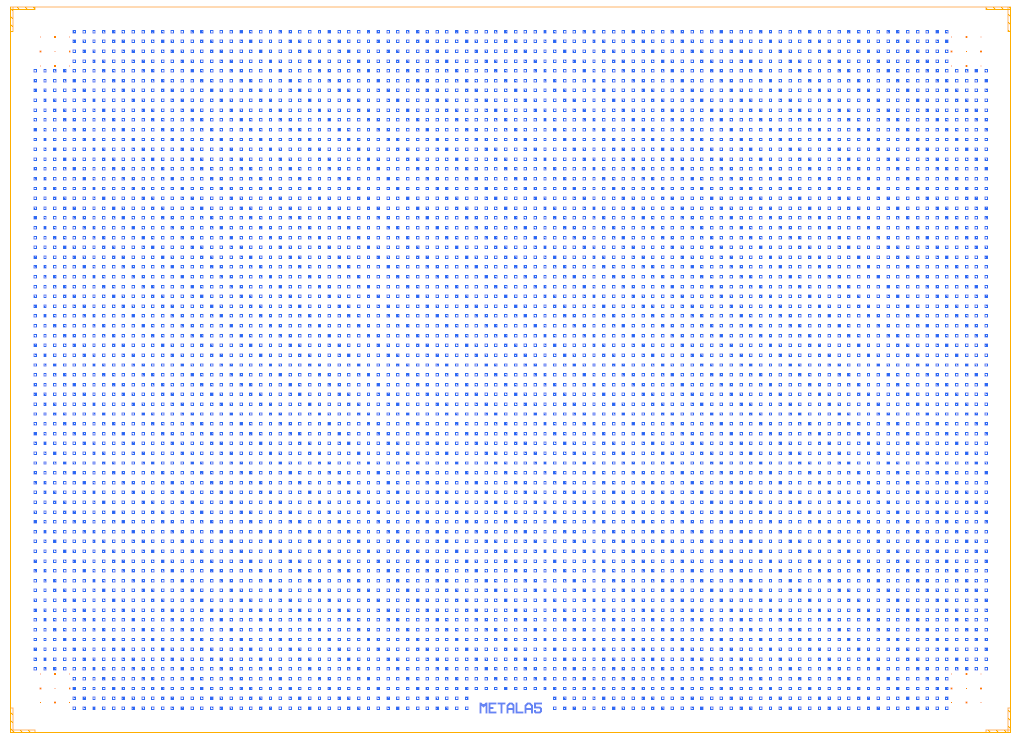

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/a5_launch_video_s1_die.png')

In [5]:
d = Designer("a5_launch_video", box=(-600, -700, 9600, 6700), chip={"name_chip": "MetalA5", "cheese": metal_cheese_rule()},
             live=LIVE)
X0, Y0 = 4500, 3000                              # Metal's 9 × 6 mm DesignPlanar chip is centred on (0, 0)
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm
CPW = dict(a=15, b=9)                            # design.variables cpw_width / cpw_gap
LP = dict(trace_width=15, trace_gap=9)           # launchpad traces (what Metal draws, see above)
R = 90                                           # Metal fillet
layout_step(d, OUT / "a5_launch_video_s1_die.png", size=(1020, 740), width=450)

## Design 2 · Bond pads: the four charge-line pads

The four `LaunchpadWirebond`s (`P<k>_C`, `lead_length` 0) sit near the corners, two on the north edge and two on the
south; each will feed one qubit's charge line (segment 7). On the grown die the source's pads sit 628–830 µm from the
die edge. In the Quantcore PDK the outer etch edge of every bond pad sits **`frame.pad_edge` = 100 µm from the die
edge**, whatever the source did: the last item of each tuple below is the edge, and `edge=` slides the pad
perpendicular to it until it is there, keeping its position along the edge (the lines that leave a pad along its axis
only get longer).

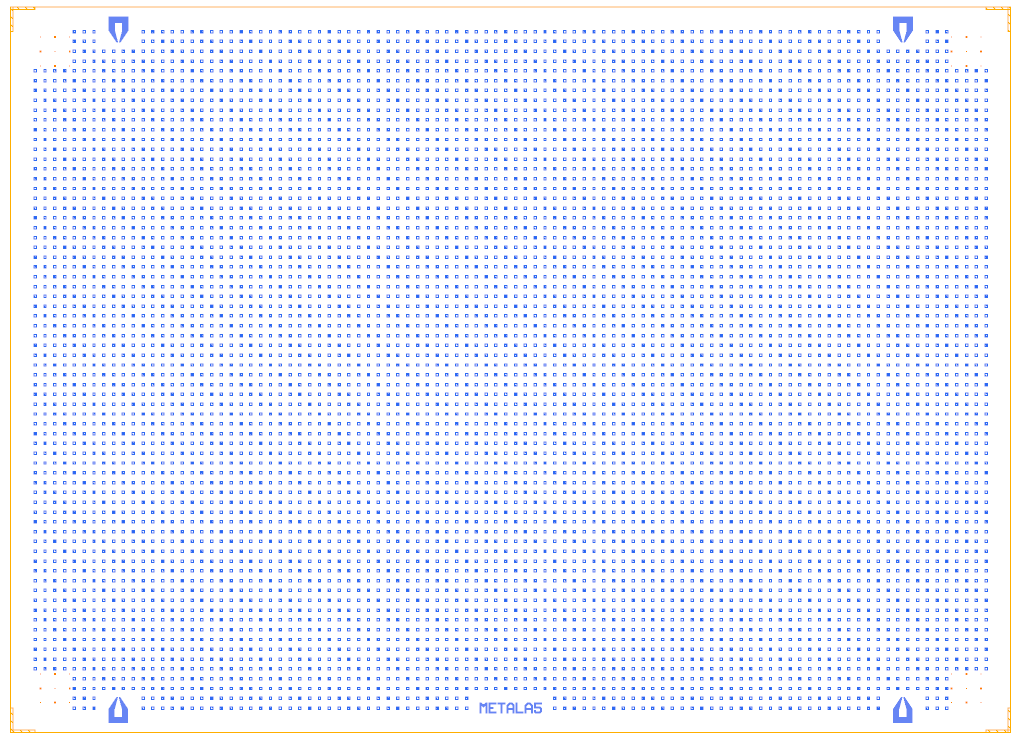

**On the chip so far:** 4 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 4 component(s) `P1_C`, `P2_C`, `P3_C`, `P4_C`.

WindowsPath('examples/designs/metal/a5_launch_video_s2_pads.png')

In [6]:
with d.batch():
    pc = {k: d.add(f"P{k}_C", "metal:LaunchpadWirebond", at=P(x, y), rot=r, lead_length=0, edge=e, **LP)
          for k, x, y, r, e in ((1, 4000, 2812, 270, "n"), (2, 4000, -2812, 90, "s"), (3, -4000, -2812, 90, "s"),
                                (4, -4000, 2812, 270, "n"))}
layout_step(d, OUT / "a5_launch_video_s2_pads.png", size=(1020, 740), width=450)

## Design 3 · Readout: the four coupled launchpads

This chip has no shared feedline: each qubit is read out through its own λ/2 resonator into its own pad, a
`LaunchpadWirebondCoupled` (`P<k>_Q`, `lead_length` 0: a bond pad with a series capacitor at its `tie`), so the
resonator (segment 5) ends on a capacitor, not on the 50 Ω line. The same pad rule puts them 100 µm from the east,
south, west and north edges; the readout meanders keep their total length and absorb the longer leads. The table
measures every pad's distance on the built layout; the picture zooms on the east pad `P1_Q`.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| P1_C | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| P2_C | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| P3_C | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| P4_C | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| P1_Q | `metal:LaunchpadWirebondCoupled` | e | 100.0 | ✓ |
| P2_Q | `metal:LaunchpadWirebondCoupled` | s | 100.0 | ✓ |
| P3_Q | `metal:LaunchpadWirebondCoupled` | w | 100.0 | ✓ |
| P4_Q | `metal:LaunchpadWirebondCoupled` | n | 100.0 | ✓ |

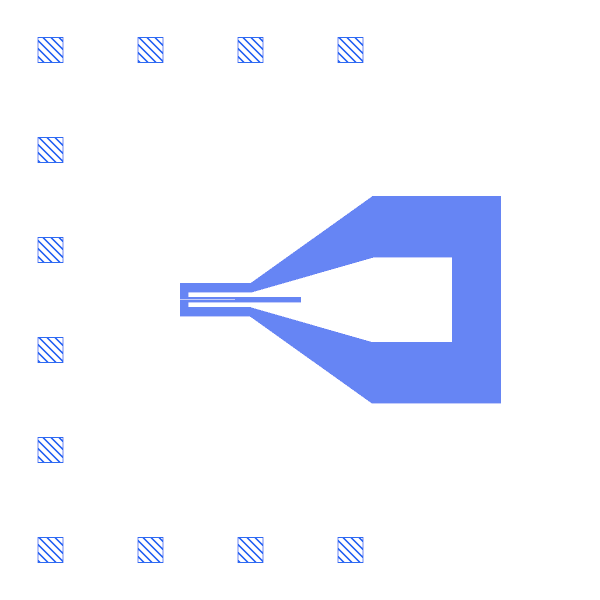

**On the chip so far:** 8 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 4 component(s) `P1_Q`, `P2_Q`, `P3_Q`, `P4_Q`.

WindowsPath('examples/designs/metal/a5_launch_video_s3_readout_pads.png')

In [7]:
with d.batch():
    pq = {k: d.add(f"P{k}_Q", "metal:LaunchpadWirebondCoupled", at=P(x, y), rot=r, lead_length=0, edge=e, **LP)
          for k, x, y, r, e in ((1, 4020, 0, 180, "e"), (2, -990, -2812, 90, "s"), (3, -4020, 0, 0, "w"),
                                (4, 990, 2812, 270, "n"))}
rebuild(d)
display(Markdown(pads_md(d)))
px, py = port_xy(d, "P1_Q.tie")
layout_step(d, OUT / "a5_launch_video_s3_readout_pads.png", box=(9000, py - 300, 9600, py + 300), size=(600, 600),
            width=300)

## Design 4 · Qubit placement: four pocket transmons

**The qubits.** `metal:TransmonPocket` is Metal's pocket transmon drawn by the wrapper with the tutorial's options:
two 425 µm pads in a 650 µm pocket and three connection pads — `a` (200 µm wide, to the readout), `b` (30 µm high) and
`c` (50 µm high) to the two ring buses. The different `b` / `c` pad heights detune each bus-coupled pair (30 µm pad at
one qubit, 50 µm at the other), so the pairs do not hybridise. The four qubits are the same cell at 0°, 270°, 180°
and 90°.

**The junctions.** The source's `Fake_Junctions` carry no value and the tutorial states no target, so every qubit
gets the PDK nominal Quantcore trilayer junction (fingers 0.5 × 0.6 µm on 2/0 + 4/0, a 50/0 spacer with the
51–53/0 dose gradient, R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF); `trilayer_junction` returns its L_J and C_J for the LOM
and the FEM junction port (`junction=`).

The first picture is the chip so far; the second zooms on Q1 (its three connection pads; the charge-line tip beside
it comes in segment 7).

junction: {'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}
Q1 ports: ['a', 'b', 'c', 'squid_a', 'squid_b']


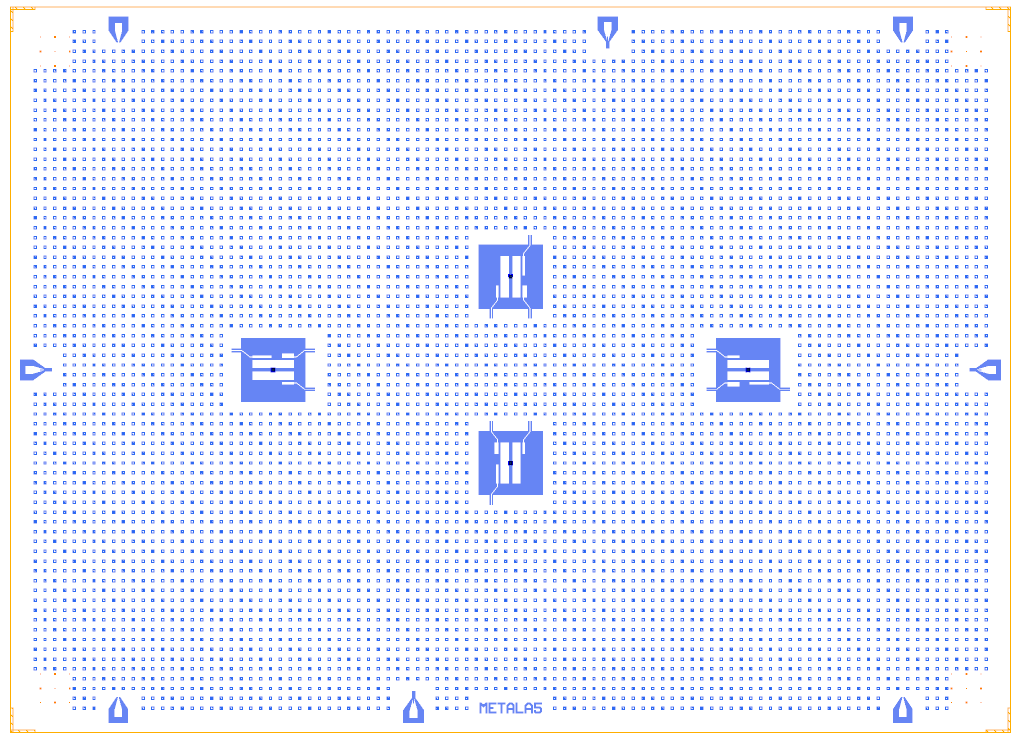

**On the chip so far:** 8 pads · 4 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 4 component(s) `Q1`, `Q2`, `Q3`, `Q4`.

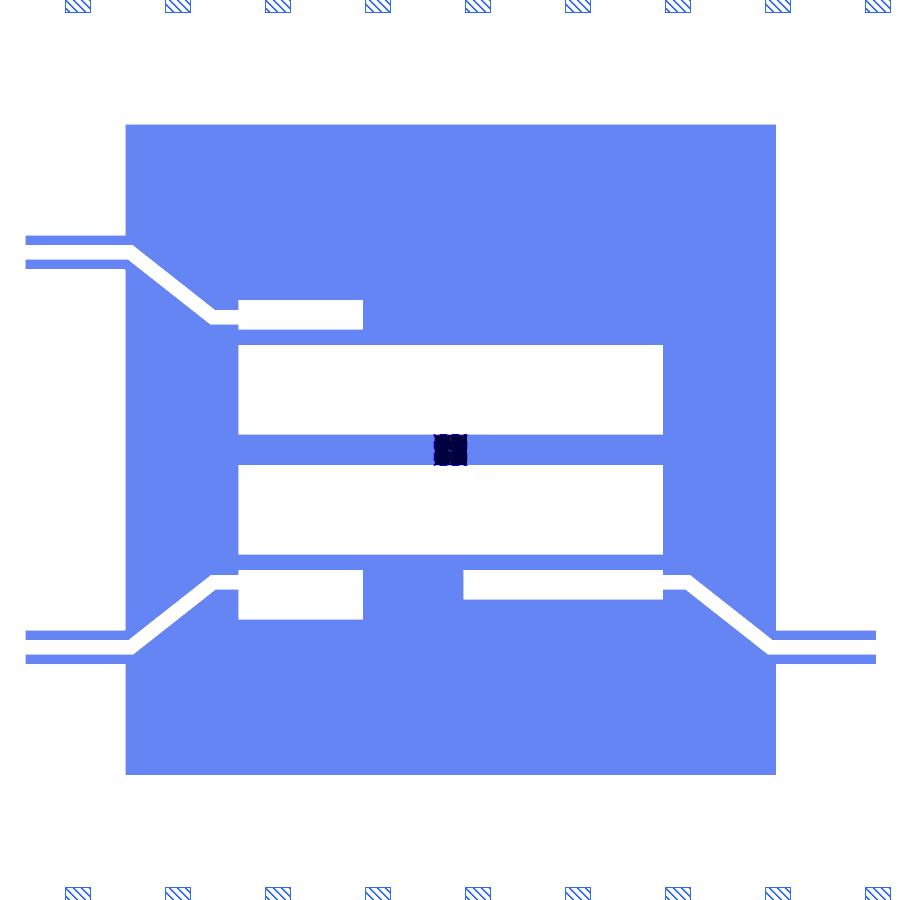

WindowsPath('examples/designs/metal/a5_launch_video_step_parts.png')

In [8]:
# Quantcore trilayer junction on the PDK rule (Nb Δ 1.4 meV): nominal fingers 0.5 × 0.6 µm → R_n 45 kΩ,
# L_J 6.73 nH, C_J 15 fF. JJ_PARAMS = {"junction_type": "Quantcore Junction"}; JUNCTION = its {Lj_nH, Cj_fF}
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonPocket")
print("junction:", JJ_PARAMS, JUNCTION)
with d.batch():
    pin = dict(cpw_width=15, cpw_gap=9)             # Metal: the design variables cpw_width / cpw_gap
    pads = {"a": {"loc_W": 1, "loc_H": -1, "pad_width": 200, **pin},
            "b": {"loc_W": -1, "loc_H": 1, "pad_height": 30, **pin},
            "c": {"loc_W": -1, "loc_H": -1, "pad_height": 50, **pin}}
    tp = dict(pad_width=425, pocket_height=650, connection_pads=pads, junction=JUNCTION, **JJ_PARAMS)
    q1 = d.add("Q1", "metal:TransmonPocket", at=P(2422.51, 0), rot=0, **tp)
    q2 = d.add("Q2", "metal:TransmonPocket", at=P(0, -950), rot=270, **tp)
    q3 = d.add("Q3", "metal:TransmonPocket", at=P(-2422.51, 0), rot=180, **tp)
    q4 = d.add("Q4", "metal:TransmonPocket", at=P(0, 950), rot=90, **tp)
print("Q1 ports:", sorted(q1.ports))
layout_step(d, OUT / "a5_launch_video_s4_qubits.png", size=(1020, 740), width=450)
qx, qy = P(2422.51, 0)
snap(d, OUT / "a5_launch_video_step_parts.png", box=(qx - 450, qy - 450, qx + 450, qy + 450), size=(900, 900), width=360)

## Design 5 · Readout: the four λ/2 readout resonators

Fixed-length λ/2 routes from each qubit's `a` pad to its coupled launchpad (`ol1`–`ol4`; 5500 µm east / west,
13 000 µm south / north; the 15/9 µm CPW). The waypoints keep them clear of the charge lines that come in segment 7:
`ol1` / `ol3` run down (up) beside them, `ol2` / `ol4` as one long meander under (over) the ring; `ol3` / `ol4` are
the point mirrors of `ol1` / `ol2` through the chip centre, as in the source. The router puts the length the waypoint
path leaves over into one KQC `Meander` on the longest free straight (turn radius 90 µm, Metal's fillet), so the
footprints differ from Metal's shifted meanders, not the lengths.

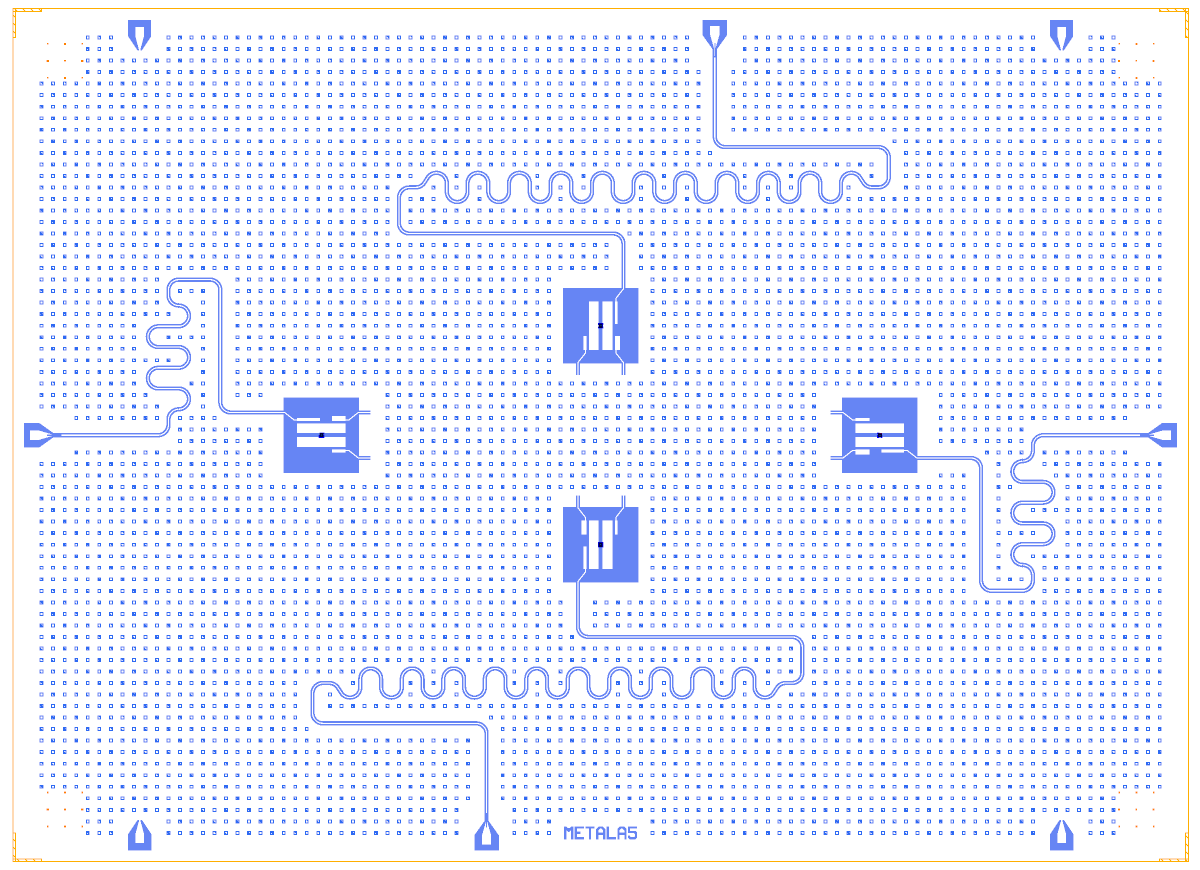

**On the chip so far:** 8 pads · 4 qubits · 0 other components · 4 routes · 0 declared couplings. **This step added** 4 route(s) `ol1`, `ol2`, `ol3`, `ol4`.

WindowsPath('examples/designs/metal/a5_launch_video_s5_readouts.png')

In [9]:
with d.batch():
    # readouts: ol1/ol3 down (up) beside the charge lines, ol2/ol4 one long meander under (over) the ring;
    # ol3/ol4 are the point mirrors of ol1/ol2 through the chip centre, as in the source
    M = lambda pts: [(2 * X0 - x, 2 * Y0 - y) for x, y in pts]
    path1 = [(7800, 2802.5), (7800, 1650), (8250, 1650), (8250, 3000)]
    path2 = [(4302.5, 1250), (6250, 1250), (6250, 850), (2000, 850), (2000, 500), (3510, 500)]
    for k, q, L, nodes in ((1, q1, 5500, path1), (2, q2, 13000, path2), (3, q3, 5500, M(path1)), (4, q4, 13000, M(path2))):
        d.route(f"ol{k}", q.a, pq[k].tie, meander=L, r=R, nodes=nodes, **CPW)
layout_step(d, OUT / "a5_launch_video_s5_readouts.png", size=(1200, 870), width=480)

## Design 6 · Coupling: a ring of four λ/2 buses

Four fixed-length λ/2 routes between neighbouring qubits' `b` / `c` pads (`cpw1`–`cpw4`, 5600 / 5700 µm, the
15/9 µm CPW) close the ring. Their turn radius is 50 µm (Metal 90 µm) so the two meander rows fit in the 400 µm
between the pads. The different `b` / `c` pad heights (30 / 50 µm, segment 4) detune each bus-coupled pair, so the
pairs do not hybridise.

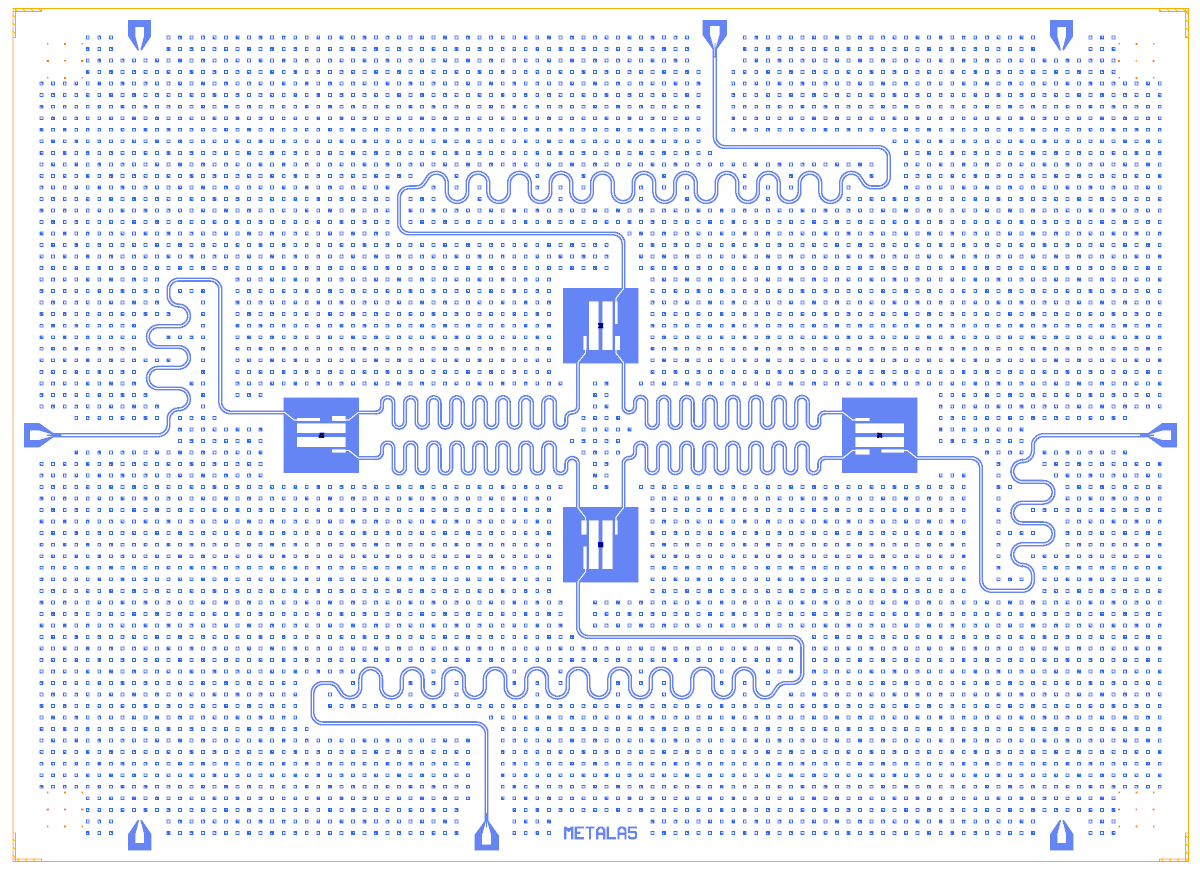

**On the chip so far:** 8 pads · 4 qubits · 0 other components · 8 routes · 0 declared couplings. **This step added** 4 route(s) `cpw1`, `cpw2`, `cpw3`, `cpw4`.

WindowsPath('examples/designs/metal/a5_launch_video_s6_buses.png')

In [10]:
with d.batch():
    RB = 50                                      # ring-bus fillet (Metal 90): the two meander rows fit 400 µm apart
    d.route("cpw1", q1.c, q2.b, meander=5600, r=RB, **CPW)
    d.route("cpw2", q3.b, q2.c, meander=5700, r=RB, **CPW)
    d.route("cpw3", q3.c, q4.b, meander=5600, r=RB, **CPW)
    d.route("cpw4", q1.b, q4.c, meander=5700, r=RB, **CPW)
layout_step(d, OUT / "a5_launch_video_s6_buses.png", size=(1200, 870), width=480)

## Design 7 · Routing: the four charge lines

**The charge-line ends.** Each `metal:OpenToGround` is the open end of a charge line, 23.5 µm outside its qubit's
pocket. Its position is the source's, on the qubit's symmetry axis, so it needs nothing from the qubit cell. A
charge line runs from each `OpenToGround` to its corner pad from segment 2 (`line_cl1`–`line_cl4`) through Metal's
`RouteAnchors` anchors, on the 15/9 µm CPW with Metal's 90 µm fillet. The tip couples equally to both pads of its
qubit, so it hardly drives the qubit mode; no drive capacitance is declared (see the intro).

OTG1 ports: ['open']


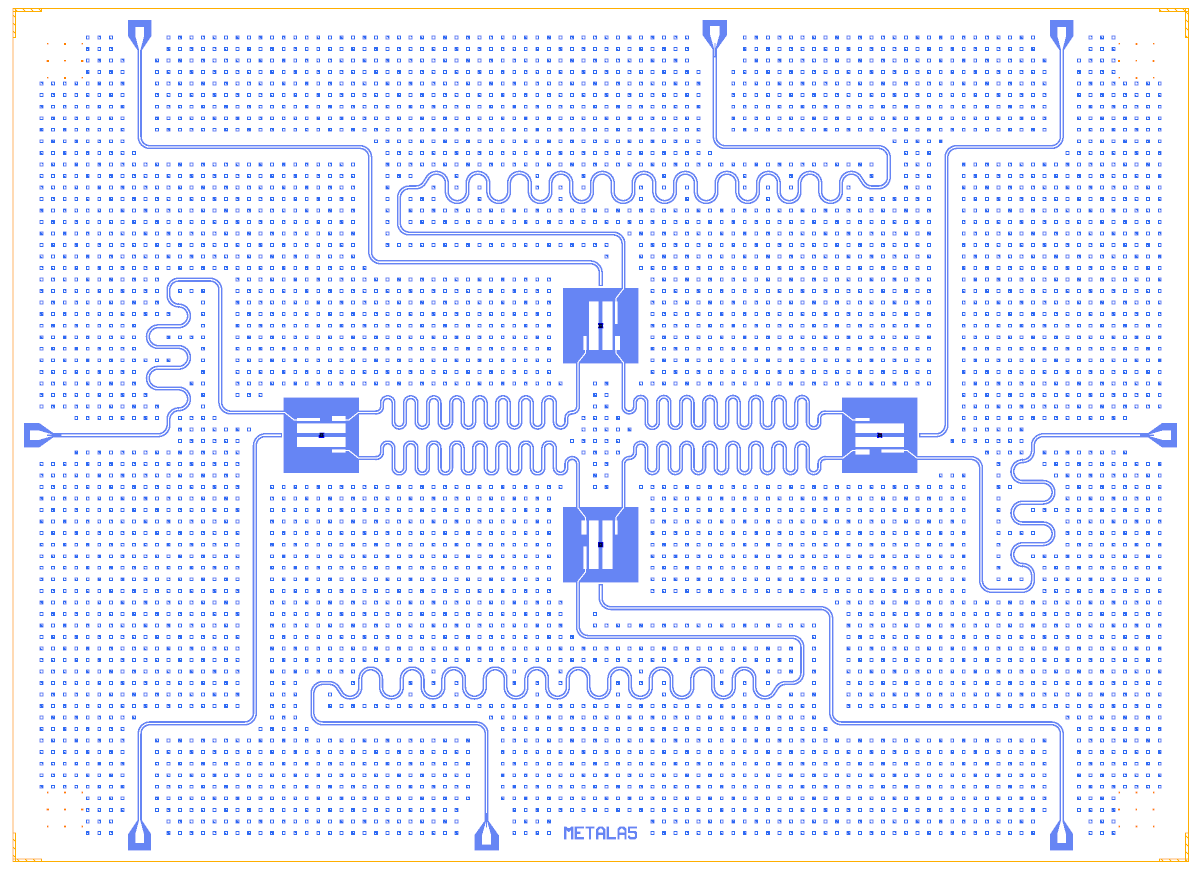

**On the chip so far:** 8 pads · 4 qubits · 4 other components · 12 routes · 0 declared couplings. **This step added** 4 component(s) `OTG1`, `OTG2`, `OTG3`, `OTG4` and 4 route(s) `line_cl1`, `line_cl2`, `line_cl3`, `line_cl4`.

WindowsPath('examples/designs/metal/a5_launch_video_s7_charge_lines.png')

In [11]:
with d.batch():
    otg = {k: d.add(f"OTG{k}", "metal:OpenToGround", at=P(x, y), rot=r, gap=9, width=15)
           for k, x, y, r in ((1, 2771, 0, 180), (2, 0, -1301, 90), (3, -2771, 0, 0), (4, 0, 1301, 270))}
    anchors = {1: [(3000, 0), (3000, 2500), (4000, 2500)], 2: [(0, -1500), (2000, -1500), (2000, -2500), (4000, -2500)],
               3: [(-3000, 0), (-3000, -2500), (-4000, -2500)], 4: [(0, 1500), (-2000, 1500), (-2000, 2500), (-4000, 2500)]}
    for k, an in anchors.items():
        d.route(f"line_cl{k}", otg[k].open, pc[k].tie, r=R, nodes=[P(*a) for a in an], **CPW)
print("OTG1 ports:", sorted(otg[1].ports))
layout_step(d, OUT / "a5_launch_video_s7_charge_lines.png", size=(1200, 870), width=480)

## Design 8 · The whole chip: sim groups, centring, save

**Sim groups** say what a FEM job cuts out of the chip: the ring (the four qubits with the four buses, Q3D C-matrix:
the core the tutorial's second video renders) and each qubit with its readout and launchpad (`Q<k>_read`, Q3D and
eigenmode). The margins make each box cut every other line once (no meander lobes inside).

**Centring.** The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of everything placed
(components and routes) and shifts the design so its centre is the die centre (pads keep their 100 µm: they slide
back to the edge along it). With pads on all four edges and the point-symmetric ring, nothing should move.

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's): the segments above changed how the chip is built, not the chip, so it should say *same design*. The
file keeps the previous key order (the routes were added in another order here), so `git diff` stays empty.

content shifted by (0.0, 0.0) µm


**Same design as before:** `examples/designs/metal/a5_launch_video.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer a5_launch_video: 16 instances, 12 routes, live=False> → examples\designs\metal\a5_launch_video.json
route lengths (µm): {'ol1': 5500, 'ol2': 13000, 'ol3': 5500, 'ol4': 13000, 'cpw1': 5600, 'cpw2': 5700, 'cpw3': 5600, 'cpw4': 5700, 'line_cl1': 4453, 'line_cl2': 5884, 'line_cl3': 4453, 'line_cl4': 5884}


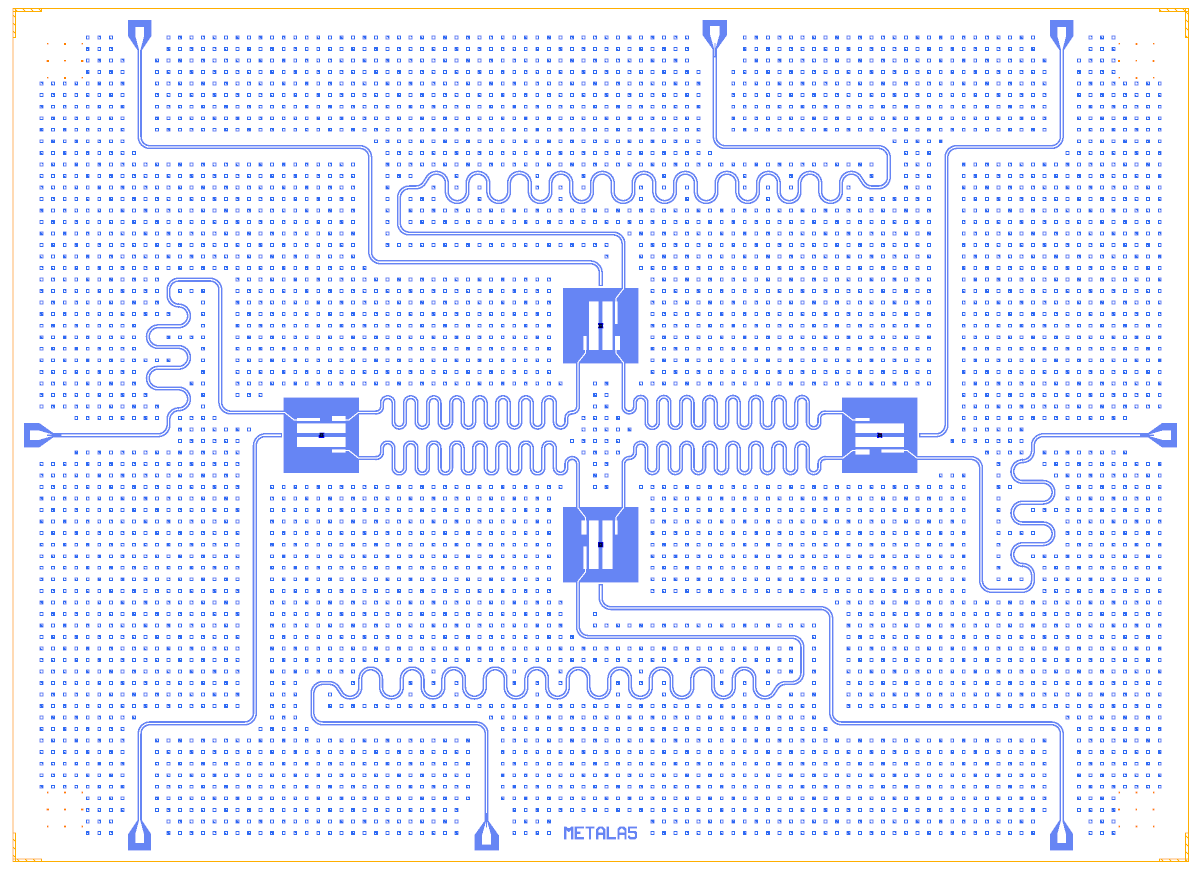

**On the chip so far:** 8 pads · 4 qubits · 4 other components · 12 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/a5_launch_video_step_routes.png')

In [12]:
# FEM boxes: margins chosen so that each box cuts every other line once (no meander lobes inside)
d.sim_group("ring", ["Q1", "Q2", "Q3", "Q4", "cpw1", "cpw2", "cpw3", "cpw4"], margin_um=150, analyses=["q3d_cmatrix"])
for k in (1, 2, 3, 4):
    d.sim_group(f"Q{k}_read", [f"Q{k}", f"ol{k}", f"P{k}_Q"], margin_um=60, analyses=["q3d_cmatrix", "eigenmode_epr"])
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
DESIGN, same = save_design(d, OUT / "a5_launch_video.json")
display(Markdown(same))
print(d, "→", DESIGN)
print("route lengths (µm):", {k: round(v) for k, v in d.result.route_lengths().items()})
layout_step(d, OUT / "a5_launch_video_step_routes.png", size=(1200, 870), width=480)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here (from the v1 run): **no errors**; eight `dangling_port` warnings (`squid_a` / `squid_b` of the four qubits, the
junctions' attachment points: the qubit cell draws the junction itself, nothing is routed there); four `overlap`
warnings, each `OpenToGround`'s box touching its qubit's pocket box (the charge-line tip sits 23.5 µm outside the
pocket, as in the source); and **no PDK design warnings** (the pads are at 100 µm, the nominal junction is in the R_n
window, the tutorial states no target).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [ ]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: a `TransmonPocket` gives two floating pad nodes with the junction
between them, plus a node per connection pad. Each bus between two pads and each readout between a pad and a coupled
launchpad (series C to its 50 Ω port) is a λ/2 `TLres`. Each charge line joins its 50 Ω launchpad to its open end
(`OTG<k>.end`) with no element to the qubit (see the intro). The port map shows where Q1's ports landed.

In [ ]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q1.", "OTG1."))})

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

Each qubit with its readout and launchpad; then each ring bus with the two qubits it joins (QuCat normal modes,
static ZZ from QuTiP). With the PDK nominal junction (numbers from the v1 run) the qubits sit near 7.0 GHz (the 10 nH assumed before the
rebuild gave 6.2 GHz); loaded, the 5.5 mm readouts and the buses sit above them and the 13 mm readouts below. The
bus-coupled pairs are detuned by the `b` / `c` pad sizes, so their ZZ is defined. The tutorial states no targets.

In [ ]:
results = simulate_groups(d, {f"Q{k}+ol{k}": [f"Q{k}", f"ol{k}", f"P{k}_Q"] for k in (1, 2, 3, 4)})
display(Markdown(groups_md(results)))
ring = {"Q1+cpw1+Q2": ["Q1", "cpw1", "Q2"], "Q3+cpw2+Q2": ["Q3", "cpw2", "Q2"],
        "Q3+cpw3+Q4": ["Q3", "cpw3", "Q4"], "Q1+cpw4+Q4": ["Q1", "cpw4", "Q4"]}
coupled = simulate_groups(d, ring, max_modes=3)
for g, res in coupled.items():
    display(Markdown(f"**{g}, QuCat normal modes:**\n\n" + modes_md(res)))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(coupled)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each simulated group (QuCat; circles are qubits, squares
resonators; filled markers are the QuTiP dressed values), (b) the dispersive shift |χ| of each readout. Here (from the
v1 run) the 5.5 mm readouts (`ol1`, `ol3`) sit ≈ 3.6 GHz above their qubits and the 13 mm ones (`ol2`, `ol4`)
≈ 2.3 GHz below, the four buses near 10 GHz.

In [ ]:
plot_lom({**results, **coupled}, OUT / "a5_launch_video_lom.png", title="a5: LOM per sub-circuit")

## LOM 3 · One geometry change, by hand

Before the FEM, a hand-made design step: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property — here the ring bus `cpw1` between Q1 and Q2, 5600 → 5400 µm — rebuild, re-run the LOM of
that bus with its two qubits and compare. A shorter λ/2 bus resonates higher (f ∝ 1/ℓ, about +3 %); the bus already
sits above the qubits (≈ 10 GHz against 7 GHz), so it moves further away: the dispersive shift and the bus-mediated
static ZZ shrink.

In [ ]:
d2 = design_copy(DESIGN)
d2["cpw1"].set(length=5400)                      # 5600 → 5400 µm
after = simulate_groups(d2, {"Q1+cpw1+Q2": ring["Q1+cpw1+Q2"]}, max_modes=3)
display(Markdown(params_delta_md({"Q1+cpw1+Q2": coupled["Q1+cpw1+Q2"]}, after)))
display(Markdown("**Static ZZ after the change:**\n\n" + zz_md(after)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/metal/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

A **Q3D C-matrix** job for the ring (four qubits with the four buses: the core the tutorial's second video
renders) and, per qubit, a C-matrix and an **eigenmode / EPR** job with its readout and launchpad (lines leaving the
box end in 50 Ω, so the mode Q gives κ).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/metal/fem/: solved results are kept here
jobs = export_sims(DESIGN)                       # Q3D C-matrix: one job per sim group
jobs_eig = export_sims(DESIGN, [f"Q{k}_read" for k in (1, 2, 3, 4)], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrices

The capacitance of each component group: `Q1_read` … `Q4_read` (the qubit's two pads, its connection pads, the
readout stub, the launchpad and the lines the box cuts, as named nets) and `ring` (the four qubits with the four
buses). Each net is named after its LOM node, so the matrix goes straight into the circuit (Results 3). `fem_stage`
solves each job with `RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The four `Q<k>_read` boxes in HFSS eigenmode: the junction is a lumped L_J ‖ C_J sheet, every line the box cuts (two
buses and the charge line) and the launchpad end in 50 Ω, so each mode's Q gives κ. pyEPR (run inside qcc's own AEDT,
never KQC's `run_pyepr_t1_estimate.py`) turns the junction's energy participation p_J into dressed frequencies, α
and χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box. The library cannot hand the solved eigenmode **mesh**
itself to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the same sim
group and box, the eigenmode job's mesh seeds (the gap and junction-island seeds that resolved the modes), the
adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before the eigenmode is solved) and a fast
sweep around it. Here for `Q1_read`.

This chip's readouts end on a pad, not on a feedline: the job's ports are the launchpad and the lines the box cuts,
so the S21 notch fit (made for hangers) may find no notch; then κ comes from the eigenmode Q (Results 2).

In [ ]:
f_r1 = results["Q1+ol1"].params.get("ol1.f_GHz")            # the LOM's readout frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "Q1_read", jobs_eig["Q1_read"][0], keep_eig["Q1_read"], f_guess=f_r1)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["Q1_read"]:
    display(Markdown(driven_md(keep_drv["Q1_read"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit; ≈ 0: the readout), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
lom_f = {}
for k in (1, 2, 3, 4):
    lom_f[f"Q{k}"] = results[f"Q{k}+ol{k}"].params.get(f"Q{k}.f_q_GHz")
    lom_f[f"ol{k}"] = results[f"Q{k}+ol{k}"].params.get(f"ol{k}.f_GHz")
plot_eigenmodes(keep_eig, OUT / "a5_launch_video_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode jobs in the LOM's terms: each qubit's mode is the one its own junction participates in most, the
readout's the remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr
terms, κ = f/Q of the 50 Ω-terminated box (bulk-dielectric loss removed). The driven run adds its notch (if any).

In [ ]:
fem_values = {}
for k in (1, 2, 3, 4):
    keep = keep_eig.get(f"Q{k}_read")
    if keep:
        fem_values[f"Q{k}"] = epr_values(keep, {f"Q{k}": f"ol{k}"}, {f"ol{k}": lom_f[f"ol{k}"]})
if keep_drv["Q1_read"]:
    fem_values.setdefault("Q1", {}).update({f"driven {k}": v for k, v in
                                            driven_values(keep_drv["Q1_read"], "ol1", f_r1).items()})
if fem_values:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(
        f"| `{k}` | {v:.5g} |" for vals in fem_values.values() for k, v in vals.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q, α, f_r, χ and κ of the four "
          "qubit / readout pairs from pyEPR, and the S21 notch of ol1.")

## Results 3 · FEM against the LOM

Two comparisons per qubit. **LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of the simulated
components by the C-matrix values (matched by net name; the other branches keep their estimates) and the same LOM
runs again. **FEM directly:** the eigenmode (pyEPR) values of Results 2. The left column is the LOM on the component
estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill

read = {f"Q{k}+ol{k}": [f"Q{k}", f"ol{k}", f"P{k}_Q"] for k in (1, 2, 3, 4)}   # the LOM 1 groups
rows = []
for k in (1, 2, 3, 4):
    g, est = f"Q{k}+ol{k}", results[f"Q{k}+ol{k}"].params
    keys = [f"Q{k}.f_q_GHz", f"Q{k}.alpha_MHz", f"ol{k}.f_GHz", f"ol{k}.chi_MHz", f"ol{k}.kappa_MHz"]
    if keep_q3d.get(f"Q{k}_read"):
        on_fem = simulate(fill(d.lom(select=read[g]).model, DESIGN, keep_q3d[f"Q{k}_read"]), max_modes=2).params
        rows += [(key, est.get(key), on_fem.get(key), "LOM on the Q3D C-matrix") for key in keys]
    for key in keys:
        if key in fem_values.get(f"Q{k}", {}):
            rows.append((key, est.get(key), fem_values[f"Q{k}"][key], "eigenmode + pyEPR"))
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrix and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards a target

The tutorial states no targets, so this notebook sets one as an exercise: **Q1 at 6.8 GHz**, ≈ 0.17 GHz lower than
the LOM puts it (from the v1 run: 6.967 GHz). It is reachable inside the PDK junction window: by the transmon formula
L_J goes from 6.73 nH to ≈ 7.1 nH, R_n ≈ 47 kΩ (`pdk_lj_bounds` keeps the feedback within 40–50 kΩ). The readout is
not targeted.

The targets go on a copy (`target_copy` → `build/a5_launch_video_target.json`), so the design file keeps its own
(none). `loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on every qubit–readout pair of the
circuit — on the Q3D values where a solve was kept — and picks one value per quantity (the consensus); a ring bus is
reached by two qubits, so it is not a readout pair. `loop.feedback` anchors a surrogate on that point and proposes
the knobs that put the target inside its tolerance (f_q ± 20 MHz); the proposal is written as revision 1, built and
netlist-checked. The revision changes the LOM's L_J; to draw the new junction, size its fingers with
`trilayer_junction(..., lj_nH=...)`. (As in the m51 pilot, whether the feedback pairs a λ/2 readout that ends on a
coupled launchpad is checked on the first run: if it says "no target reached the consensus", that is the reason.)

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

TARGETS = {"Q1": {"f_q_GHz": 6.8}}               # the exercise target (GHz); add more here
DESIGN_T = target_copy(DESIGN, TARGETS)
BOUNDS = pdk_lj_bounds(DESIGN)                   # L_J of the PDK R_n window, per junction
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until
every target is inside its tolerance or `MAX_ITER` revisions are made (`build/a5_launch_video/revisions/`). Without
`RUN_FEM` each revision is judged on the LOM. With `RUN_FEM = True` each revision's `Q1_read` Q3D job is exported and
solved first (`solve_rev`), so the loop closes on FEM values (each solve takes AEDT minutes). The table shows each
iteration's value against the target and the knob it moved; the plot the residual in tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q3D component job, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = export_sims(rev, ["Q1_read"], root=f"build/jobs/rev{k}")
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "a5_launch_video_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

The design JSON saved in Design 8 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese: the original wins.** The A.5 notebook exports its GDS with Metal's `QGDSRenderer` at its defaults, and the cheese is on by default (`cheese.view_in_file = {main: {1: True}}`: `cheese_0_x/y` 25 µm squares every `delta_x/y` 100 µm, `edge_nocheese` 200 µm, `no_cheese.buffer` 25 µm). So the original *has* cheese, and the precedence rule keeps the original's, not the PDK band. The chip carries Metal's rule as its `cheese` parameter (Design 1: `metal_cheese_rule()` = `{size, gap, rows, clearance, edge}`), so the build draws it into KQC's `ground_grid` layer over the whole free ground inside the frame's design area, clear of the 3/0 keep-outs by the buffer (the 3/0 keep-out already adds the PDK route margin round each CPW, so the holes sit a few µm further from the etch than in Metal). The layout, the snapshots and KLive show it, and `export_fab` / `qcc mask` keep it (`cheese source: build`, no PDK band added).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [ ]:
print("design file:", DESIGN)
CHEESE = True                                    # export_fab keeps the build's cheese (the original's rule)
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

## Fab 2 · Snapshots

The full chip (compare the tutorial's screenshot: same components and pins, different meander footprints); `Q1` with
its three connection pads and the charge-line tip; its trilayer junction; the east coupled launchpad where `ol1`
ends (now 100 µm from the edge); the **fab mask** round `Q1` (1/0 etch with the original's Metal cheese, the 3/0
keep-out, the junction layers); and the die frame's south-west corner (dicing L on 1000/0, alignment grid on
1001/0). Positions are read from the design (after the centring shift).

In [ ]:
QX, QY = d.data["instances"]["Q1"]["place"]["at"]
show_snapshot(d, OUT / "a5_launch_video.png", size=(1500, 1088))
show_snapshot(d, OUT / "a5_launch_video_q1.png", box=(QX - 450, QY - 450, QX + 450, QY + 450), width=420)
show_snapshot(d, OUT / "a5_launch_video_jj.png", box=(QX - 40, QY - 40, QX + 40, QY + 40), width=300)
px, py = port_xy(d, "P1_Q.tie")
show_snapshot(d, OUT / "a5_launch_video_pad.png", box=(px - 450, py - 300, px + 250, py + 300), size=(1400, 1200), width=360)
snap_file(Path("build") / "a5_launch_video_fab.oas", OUT / "a5_launch_video_cheese.png",
          box=(QX - 600, QY - 600, QX + 600, QY + 600), size=(1200, 1200), width=420)
show_snapshot(d, OUT / "a5_launch_video_frame.png", box=(-600, -700, 300, 200), size=(900, 900), width=300);

## Summary

| | |
|---|---|
| matches the source | every Metal component and option, their positions and orientations, the route end pins and lengths (buses 5600 / 5700 µm, readouts 5500 / 13 000 µm), the charge lines through Metal's anchors, the sim groups |
| PDK changes | QCT frame on the grown 10.2 × 7.4 mm box; sapphire stack; the eight launchpads 100 µm from the edges (were 628–830 µm); trilayer junctions (PDK nominal); cheese = the original's Metal cheese, drawn by the build; content centred (shift printed in Design 8) |
| differs | the meander footprints (qcc router; ring buses with a 50 µm turn radius); from the v1 run: LOM f_q 6.97 / 6.98 GHz (α ≈ −297 MHz), readouts 10.59 GHz (5.5 mm; κ 9.1 MHz, χ −2.5 MHz) and 4.68 GHz (13 mm; κ 0.82 MHz, χ −0.69 MHz), buses 9.9–10.1 GHz, static ZZ 215 / 235 kHz per bus pair (the 10 nH assumed before the rebuild gave 6.2 GHz qubits) |
| PDK design warnings | none |
| layout | built in eight segments (die, charge-line pads, readout pads, qubits, readout resonators, buses, charge lines, the whole chip); the saved JSON is the v1 notebook's |
| feedback | an exercise target on a copy (Q1 6.8 GHz): `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`) |
| open | the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells |